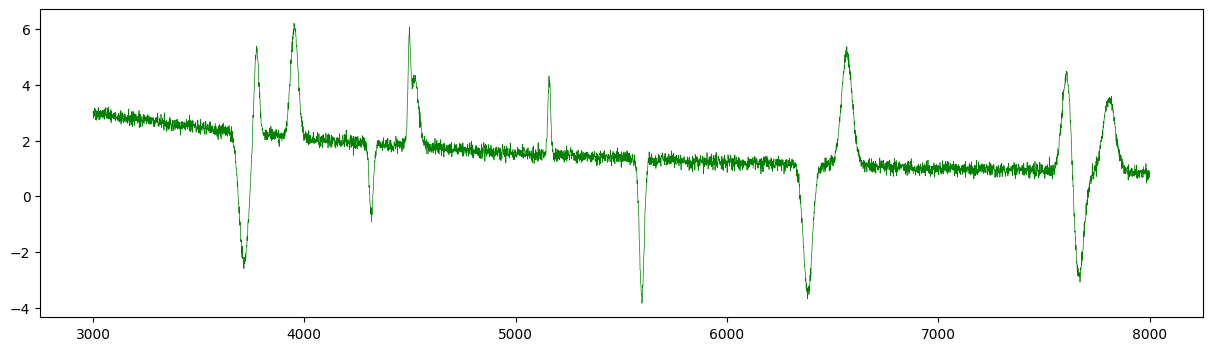

In [83]:
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

lambda_range = (3000, 8000)
number_of_lines = 13
dynamic_range = (2, 5)
std_range = (5, 30)
noise_std = 0.125
resolution = (lambda_range[1] - lambda_range[0])//1
centers = np.random.random(number_of_lines) * (lambda_range[1] - lambda_range[0]) + lambda_range[0]
widths = np.random.random(number_of_lines) * (std_range[1] - std_range[0]) + std_range[0]
heights = (2*np.random.random(number_of_lines)-1) * (dynamic_range[1] - dynamic_range[0])
heights = heights + dynamic_range[0]*heights/np.abs(heights)
plain_x = np.linspace(lambda_range[0], lambda_range[1], resolution)
lines = zip(centers, widths, heights)


full_spectrum = np.zeros_like(plain_x, dtype = float)
full_spectrum_alt = np.zeros_like(plain_x, dtype = float)

continuum = 100000*plain_x**-1.3
noise = np.random.normal(scale = noise_std, size=len(plain_x))
full_spectrum += noise #+ continuum
full_spectrum_alt += noise #+ continuum

for line in lines:
    g_line = stats.norm.pdf(plain_x, loc=line[0], scale=line[1])
    g_line = line[2] * g_line/g_line.max()
    line_weight = np.abs(g_line)/np.abs(g_line).max()
    noise_weight = stats.norm.pdf(g_line, loc=0, scale=noise_std)
    noise_weight = noise_weight/noise_weight.max()
    comb = noise*noise_weight + (1-noise_weight)*g_line
    full_spectrum += comb - noise # Clean peaks
    full_spectrum_alt += g_line # Noise everywhere

full_spectrum += continuum
full_spectrum_alt += continuum

#
fig = plt.figure(figsize = (15,4))
# plt.plot(plain_x, full_spectrum, '-', color='black', lw = 0.5)
plt.plot(plain_x, full_spectrum_alt, '-', color='green', lw = 0.5)

plt.show()


